# 27 Oct — Two arbitrary layers: thickness error and the image

A flat mirror has **two finite layers of unnamed materials A and B** on an unnamed semi-infinite substrate. Start at **40 nm**, longer than 13.5 nm. The complex refractive indices are editable **illustrative assumptions**, not measured properties of a named material. They are held fixed during wavelength sweeps; a real material would need a dispersion model.

The ideal comparison has **equal, spatially uniform layer thicknesses** at the same wavelength, total thickness, substrate, illumination and focus. We compare this reference, the true thickness-error pupil, and its Zernike reconstruction. Run All once; edit C02 or use C06. Numerical checks are in [optics_validation.ipynb](optics_validation.ipynb).


## M01 — Why choose this wavelength and equal-layer design?

Use time dependence $e^{-i\omega t}$, passive indices $\tilde n=n'+i\kappa$, and normal incidence. The default assumptions are

$$\lambda_0=40\ \mathrm{nm},\quad \tilde n_A=0.920+0.006i,\quad
\tilde n_B=0.995+0.002i,\quad\tilde n_s=0.980+0.010i.$$

Forty nm is a longer-EUV teaching wavelength; it is not tied to a lithography wavelength or a particular material pair. These assumptions give contrast and absorption without introducing measured-material complexity.

For equal layers $d_A=d_B=T/2$, the one-pass phases are $\psi_j=2\pi\tilde n_jd_j/\lambda_0$. A useful initial phase-matching scale is

$$\operatorname{Re}(\psi_A+\psi_B)\approx\pi\quad\Rightarrow\quad
T\approx\frac{\lambda_0}{\operatorname{Re}(\tilde n_A+\tilde n_B)}\approx20.89\ \mathrm{nm}.$$

This estimate alone does **not** prove an optimum when interface phases and absorption matter. We refine $T$ using the exact two-film reflection formula. With $q=(d_A-d_B)/T$ and $\mathcal R(q)=|r(q)|^2$, choose $T$ so

$$\left.\frac{\partial\mathcal R}{\partial q}\right|_{q=0}
=2\operatorname{Re}\left[r(0)^*\left.\frac{\partial r}{\partial q}\right|_0\right]=0,$$

then select a maximum, not a minimum. For the defaults this gives **$T\approx20.9881$ nm**, with each layer **10.4941 nm** and $\mathcal R(0)\approx0.7729\%$. The exact scan in C03 shows the maximum at equal thickness. We optimize **over thickness split at the selected wavelength**, not over wavelength itself.

Equal physical thickness is not universally optimal: changing the indices, wavelength, total thickness or substrate can move the optimum. It remains a valid *ideal imaging reference* because uniform $r_0$ gives $U_0=r_0U_{\rm clear}$, hence the same diffraction shape. Two films have modest reflectance; this is not a many-period commercial EUV mirror.


In [1]:
# C01 — Load the common imaging tools and the arbitrary two-film model.
from pathlib import Path
import sys
BASE_DIR=Path.cwd()
if not (BASE_DIR/'mirror_dent_optics.py').exists():
    candidate=BASE_DIR/'Discussion Series'/'27 Oct'
    if candidate.exists():BASE_DIR=candidate
sys.path.insert(0,str(BASE_DIR))
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display,Markdown
if get_ipython() is not None:get_ipython().run_line_magic('matplotlib','inline')
import mirror_dent_optics as optics

import euv_bilayer_optics as coating


## M02 — Editable controls and the bounded thickness error

Define nominal deviation $s=\delta/100\in[-1,1]$, nonuniformity strength $\alpha\in[0,1]$, and a Gaussian profile $G=\exp[-((u-u_0)^2+(v-v_0)^2)/F]\in[0,1]$:

$$q(u,v)=s+\alpha s(1-|s|)G(u,v),\qquad
d_A=\frac T2(1+q),\qquad d_B=\frac T2(1-q).$$

Then $d_A+d_B=T$ at every pupil location and $|q|\le |s|(2-|s|)\le1$. The slider is the **nominal background split deviation**; a local profile increases its magnitude near the defect, while staying bounded. The thickness maps show the actual local values.

- $\delta=0$: equal layers everywhere, the ideal reference.
- $\delta=+100$: all A and no B over the entire mirror.
- $\delta=-100$: all B and no A over the entire mirror.
- $\alpha=0$: a uniform split change—brightness/global phase can change, but normalized image shape does not.
- $\alpha>0$: spatially varying composition, so both amplitude and phase can vary across the pupil.

The top and bottom planes stay fixed: this is a **buried-interface/composition error**, with no additional geometric surface-sag phase.

| Parameters | Meaning |
|---|---|
| wavelength_nm | 20–120 nm, default 40; not fixed to 13.5 nm |
| nA_real, nA_imag; nB_real, nB_imag | Editable complex indices of the arbitrary films; imaginary parts are nonnegative |
| nS_real, nS_imag | Complex index of the unnamed semi-infinite substrate |
| total_thickness_nm | Fixed total $T$; C02 initially calibrates it for equal-thickness maximum reflectance |
| deviation_percent, nonuniformity | Nominal split in −100…+100%, and strength of its spatial variation |
| area_fraction, center_u, center_v | Width and location of $G$; pupil-radius units |
| n_max | Integer radial truncation degree for the complex-pupil fit |
| n_pupil, fft_pad; quad_radial, quad_angular | Independent image-grid and coefficient quadrature controls |
| added_defocus_nm | Same chosen focus in every comparison |
| scene_kind and feature dimensions | Same incoherent-object options as the visible notebook |

If you edit wavelength or indices, rerunning C02 attempts to recalibrate $T$ near the phase-matching estimate. Some choices have no equal-split reflectance maximum in that search interval; then choose other indices or enter $T$ manually and use equal layers solely as the uniform imaging reference. Sliders vary the chosen settings independently so you can also inspect detuning. Reflectance is calculated self-consistently from indices and thicknesses, rather than entered as a disconnected intensity factor.


In [2]:
# C02 — EDIT these illustrative optical constants and the longer-EUV wavelength.
WAVELENGTH_NM=40.0
N_A=0.920+0.006j
N_B=0.995+0.002j
N_SUBSTRATE=0.980+0.010j
T_DESIGN=coating.equal_split_design(WAVELENGTH_NM,N_A,N_B,N_SUBSTRATE)
P=coating.CoatingParameters(
    wavelength_nm=WAVELENGTH_NM,total_thickness_nm=T_DESIGN,
    nA_real=N_A.real,nA_imag=N_A.imag,nB_real=N_B.real,nB_imag=N_B.imag,
    nS_real=N_SUBSTRATE.real,nS_imag=N_SUBSTRATE.imag,
    deviation_percent=40.0,nonuniformity=1.0,
    area_fraction=0.10,center_u=0.0,center_v=0.0,
    n_max=8,n_pupil=192,fft_pad=4,quad_radial=64,quad_angular=128,
    added_defocus_nm=0.0,scene_kind='mixed',
)
ORDERS=[0,2,4,6,8,10,12,16]
SAVE=True
print(f'Chosen wavelength = {P.wavelength_nm:g} nm; total = {T_DESIGN:.6f} nm; equal layers = {T_DESIGN/2:.6f} nm each')


Chosen wavelength = 40 nm; total = 20.988147 nm; equal layers = 10.494073 nm each


## M03 — Reflection is a complex field coefficient

For $r_{ij}=(\tilde n_i-\tilde n_j)/(\tilde n_i+\tilde n_j)$, the exact locally planar two-film recursion is

$$r_{A|Bs}=\frac{r_{AB}+r_{Bs}e^{2i\psi_B}}{1+r_{AB}r_{Bs}e^{2i\psi_B}},\qquad
r=\frac{r_{0A}+r_{A|Bs}e^{2i\psi_A}}{1+r_{0A}r_{A|Bs}e^{2i\psi_A}}.$$

Changing the split changes both $|r|$ and $\arg r$. The curves below use **uniform** splits to show the material/interference response; the image experiment uses the spatial map defined above. Every reflection coefficient is referred to the same fixed top plane. At a zero-thickness endpoint the interface identities collapse the stack to the corresponding single finite film.


Equal-layer r = +0.086903-0.013291i; power reflectance = 0.77288%


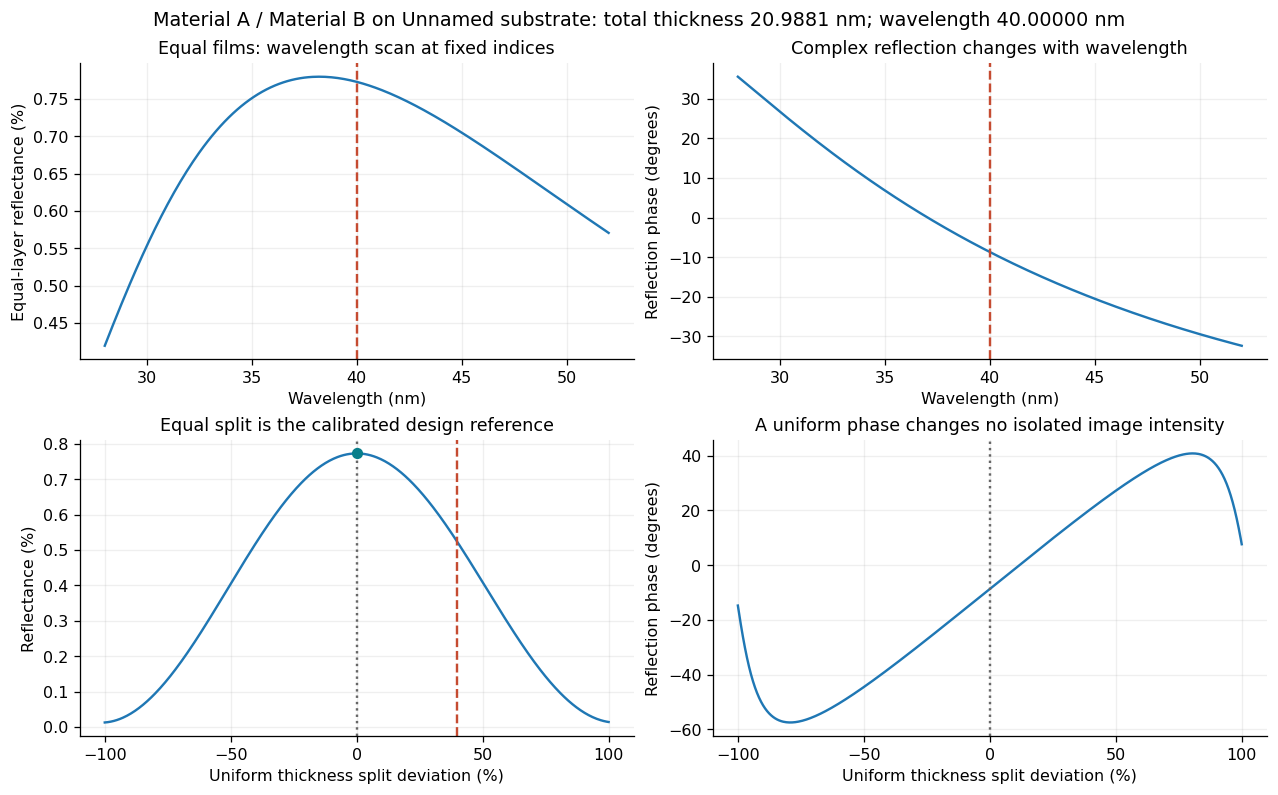

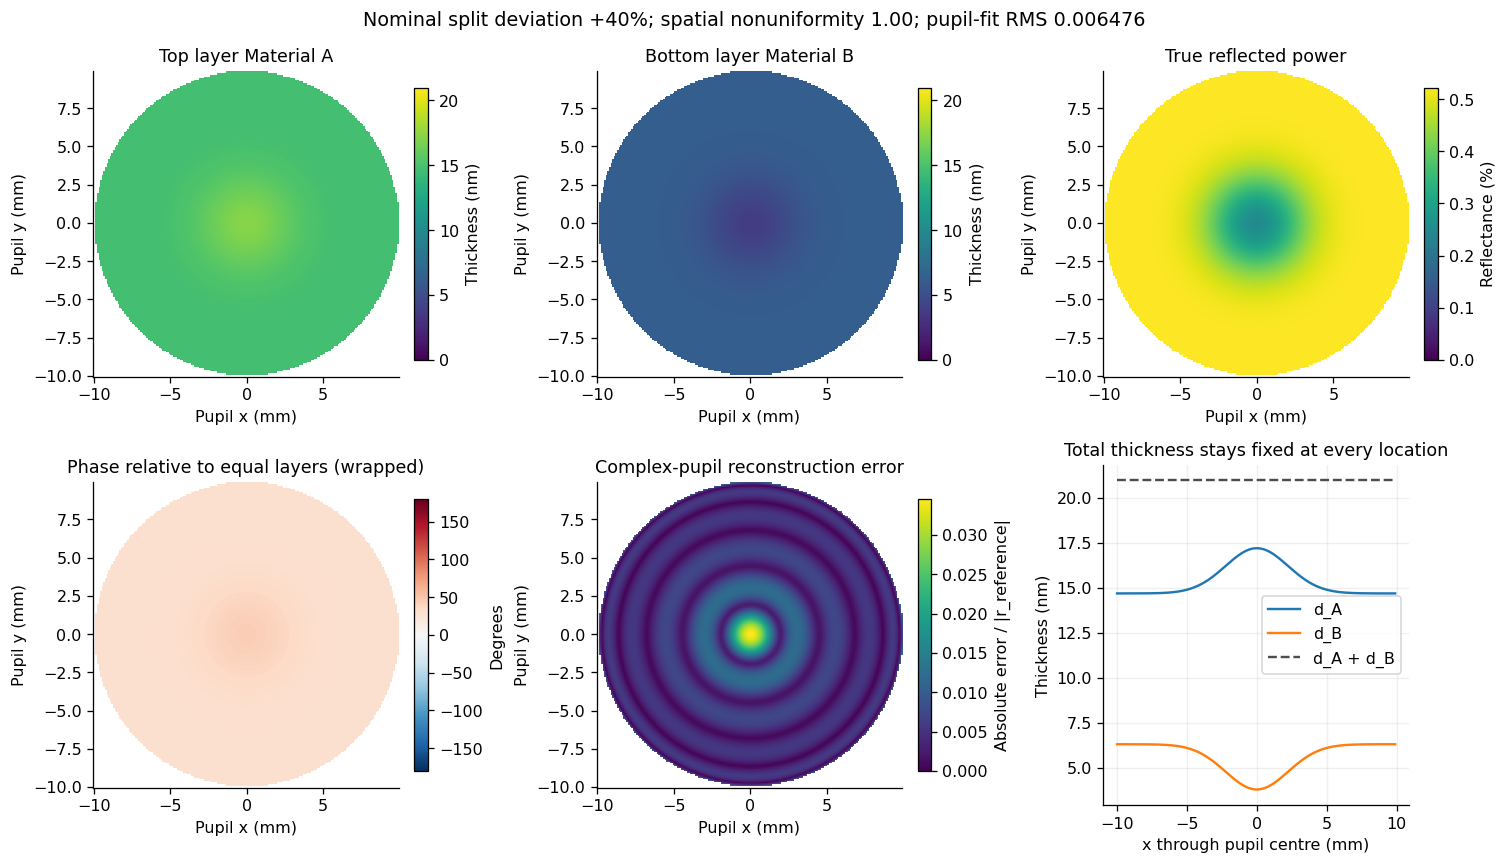

In [3]:
# C03 — Design response, actual thickness maps, and the complex pupil.
CASE=coating.coating_study(P)
FIGURES={}
r0=CASE['r_reference']
print(f'Equal-layer r = {r0.real:+.6f}{r0.imag:+.6f}i; power reflectance = {100*abs(r0)**2:.5f}%')
for name,make in [('01_design_response',coating.plot_design),('02_thickness_and_pupil',coating.plot_coating_maps)]:
    FIGURES[name]=make(P if name=='01_design_response' else CASE)
    display(FIGURES[name]);plt.close(FIGURES[name])


## M04 — Zernike reconstruction includes amplitude and phase

A coating error is generally not phase-only, so fitting OPD alone would discard information. Expand the **complex relative pupil** in the same real, unit-mean-square Zernike basis:

$$C=\frac{r(u,v)}{r_0},\qquad c_j=\langle CZ_j\rangle,\qquad
\widehat r=r_0\sum_j c_jZ_j.$$

Here $\langle\cdot\rangle$ is the uniform full-disk average, as in the visible notebook. For an obscured pupil, use the weighted least-squares coefficients computed by the helper instead of the full-disk projection formula. The coefficients have complex, dimensionless values. Their real and imaginary parts are shown separately; they are **not OPD coefficients in nm**. This fit avoids phase-unwrapping ambiguity. The phase map is explicitly labelled as wrapped. We propagate $A r$ and $A\widehat r$ independently and square the fields to compare images.


,n,m,Re_c,Im_c,abs_c
0,0,0,6.872409e-01,4.053279e-01,7.978664e-01
4,2,0,4.277040e-02,-6.304971e-03,4.323262e-02
12,4,0,-3.613017e-02,3.471236e-03,3.629654e-02
24,6,0,2.326606e-02,-1.060456e-04,2.326630e-02
40,8,0,-1.216617e-02,-1.833595e-03,1.230357e-02
44,8,8,-7.137535e-17,-3.918169e-17,8.142263e-17
9,3,3,-6.024473e-17,-3.188003e-17,6.815984e-17
20,5,5,-4.635624e-17,-2.591647e-17,5.310899e-17
34,7,5,4.094594e-17,2.333060e-17,4.712629e-17
15,5,-5,3.629298e-17,2.222886e-17,4.255940e-17


,on_axis_ratio,sampled_peak_ratio,energy_in_0p61,throughput
case,,,,
ideal,0.007729,0.007729,0.838066,0.007729
true,0.004920,0.004920,0.808010,0.004950
recon,0.004920,0.004920,0.808047,0.004950


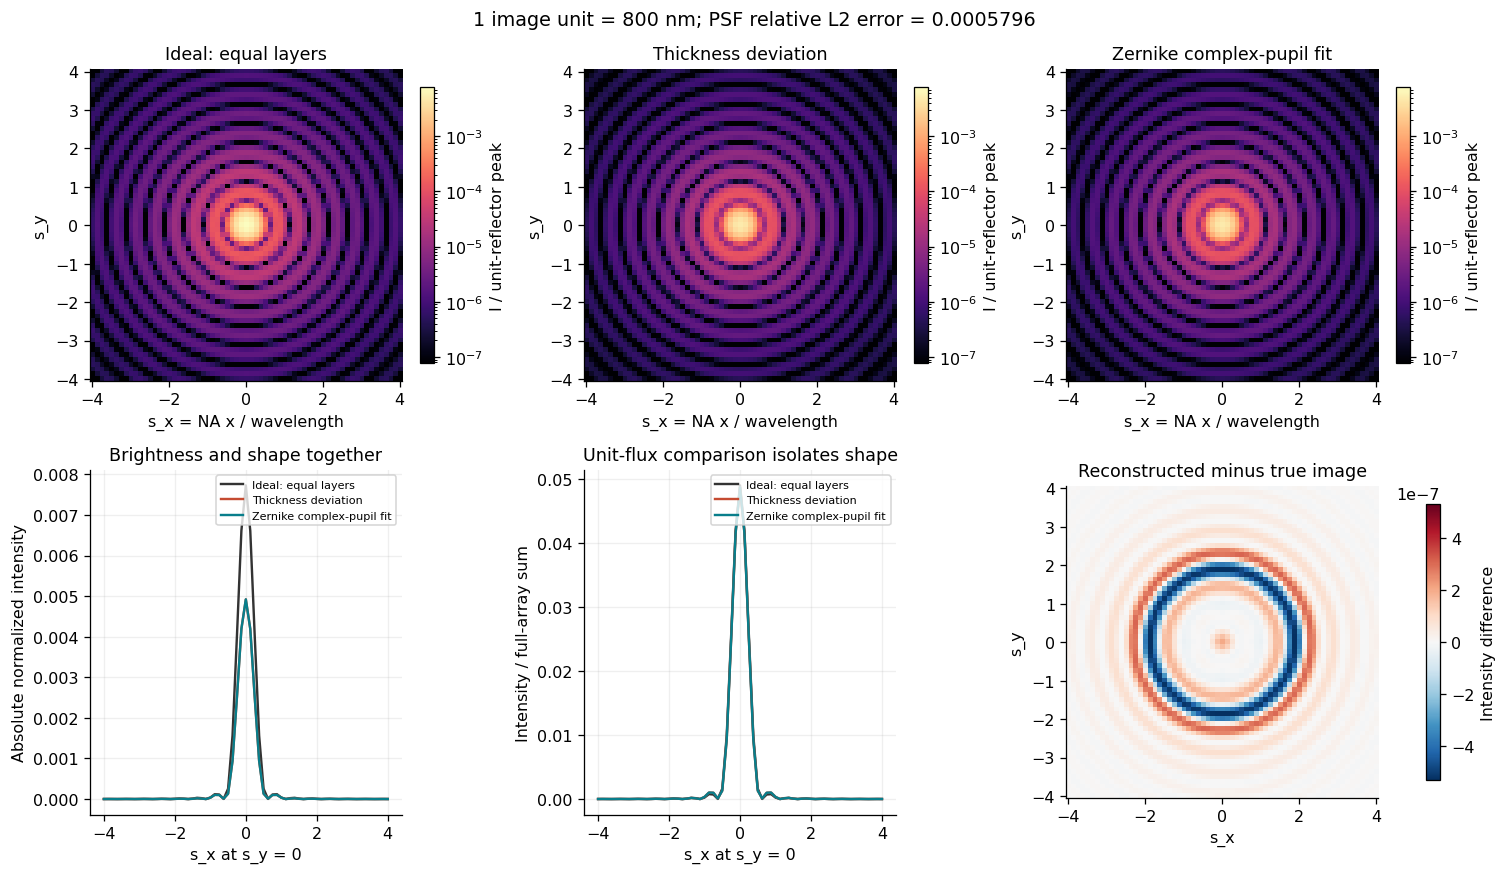

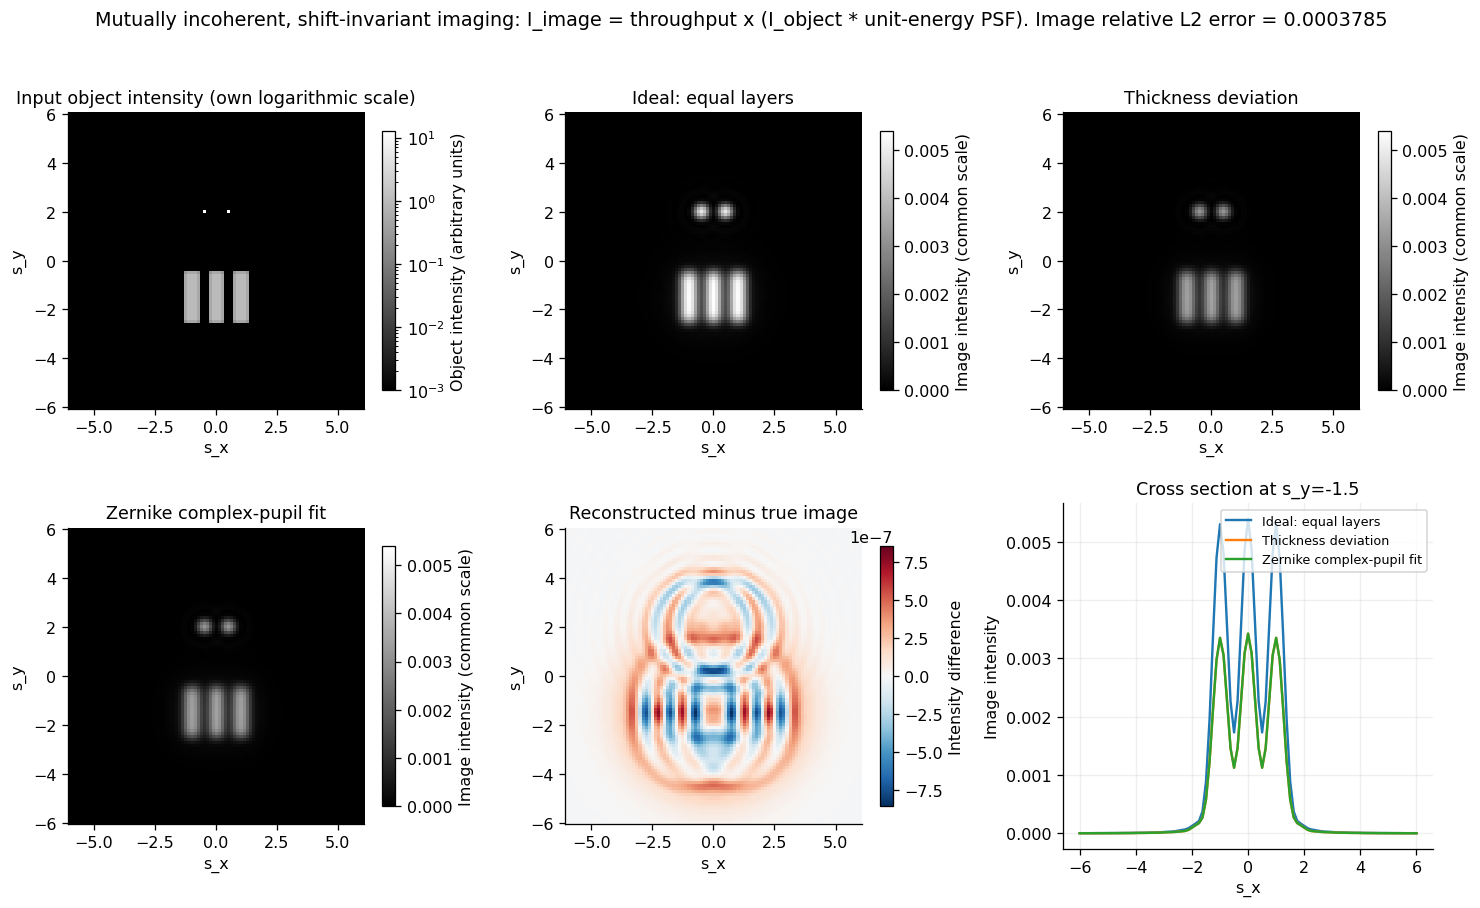

In [4]:
# C04 — Inspect coefficients, then compare point and object images.
display(CASE['coefficients'].sort_values('abs_c',ascending=False).head(12))
display(CASE['metrics'].drop(columns='discrete_total_intensity').round(7))
for name,make in [('03_point_images',coating.plot_coating_psfs),('04_object_images',optics.plot_scene)]:
    FIGURES[name]=make(CASE);display(FIGURES[name]);plt.close(FIGURES[name])


## M05 — Reconstruction order and image shape

The images keep the absolute reflected-power change. The separately labelled **unit-flux** cross section removes total flux solely to compare shape. With spatial nonuniformity set to zero, those shape curves should coincide even though raw images may differ in brightness. A spatially varying $r$ can change shape as well as power. The convergence plots use integer orders.


,n_max,mode_count,complex_pupil_rms,psf_relative_L2
0,0,1,0.062619,0.028554
1,2,6,0.045300,0.011559
2,4,15,0.027104,0.004216
3,6,28,0.013904,0.001536
4,8,45,0.006476,0.000580
5,10,66,0.002969,0.000195
6,12,91,0.001413,0.000061
7,16,153,0.000323,0.000004


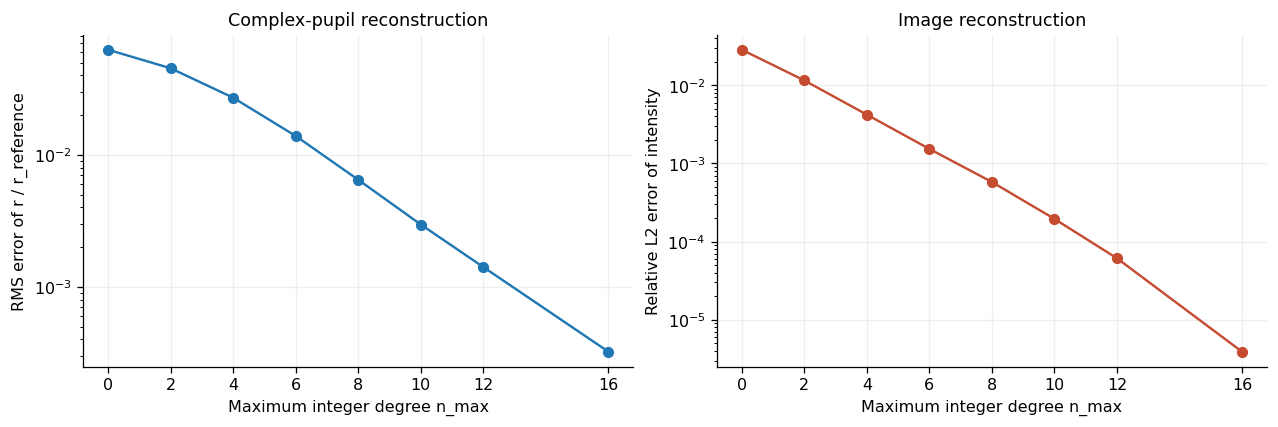

In [5]:
# C05 — Finite-basis reconstruction of the same thickness-error pupil.
CONVERGENCE=coating.coating_convergence(P,ORDERS)
display(CONVERGENCE)
FIGURES['05_order_convergence']=coating.plot_coating_convergence(CONVERGENCE)
display(FIGURES['05_order_convergence']);plt.close(FIGURES['05_order_convergence'])


## M06 — Interactive controls

Try −100, 0 and +100% first. Then compare spatial nonuniformity 0 and 1 at the same intermediate deviation. Wavelength, total thickness and the complex indices tune the reflection coefficient; equal thickness remains the uniform imaging reference when the reflectance optimum moves. No top-surface dent is added in this notebook.


In [6]:
# C06 — Live controls: click Compute after changing a set of values.
DASHBOARD=coating.coating_dashboard(P)
display(DASHBOARD['ui'])


## M07 — Save and inspect the model

C07 saves parameters, complex coefficients, thickness/pupil arrays, images and provenance to results/euv. To save a successful interactive case, use <code>coating.export_coating(DASHBOARD['state']['study'], directory=BASE_DIR/'results'/'euv_interactive')</code>.

The model is scalar, paraxial, normal-incidence and locally planar. It neglects interface roughness, interdiffusion, vector effects, lateral coupling within the films and material dispersion. The selected indices are arbitrary assumptions at the chosen wavelength, with no named-material claim. The formulas build on Chapters 5–7 of the local [textbook](../../aberration%20budget%20paper/aberration_budget_textbook.pdf). Independent optical and numerical checks are in [optics_validation.ipynb](optics_validation.ipynb); implementation is in [euv_bilayer_optics.py](euv_bilayer_optics.py).


In [7]:
# C07 — Optional baseline export; choose another folder to retain another case.
if SAVE:coating.export_coating(CASE,CONVERGENCE,FIGURES,BASE_DIR/'results'/'euv')


Saved to C:\Users\fxl04\Desktop\Prof. Wong Grp Papers\Discussion Series\27 Oct\results\euv
